<a href="https://colab.research.google.com/github/SurenderguliaEnginner/PlayStore-App-Review-EDA/blob/main/PlayStore_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project Name**    -Play Store App Review Analysis



**Project Type**    - EDA
##### **Contribution**    - Individual


# **Project Summary -**

This project analyses the Google Play Store data to find the factors that drive app engagement and success. The Android market is huge, and developers need clear, data-backed insights on what makes an app popular. Using exploratory data analysis (EDA), this project studies how rating, reviews, installs, price, category and user sentiment relate to each other, and turns the findings into practical advice for app developers and businesses.

Two datasets were used. The first, Play Store Data, has 10,841 rows and 13 columns, including App, Category, Rating, Reviews, Size, Installs, Type, Price, Content Rating, Genres, Last Updated, Current Version and Android Version. The second, User Reviews, has 64,295 rows with the translated review text, its sentiment (Positive, Neutral or Negative), and sentiment polarity and subjectivity scores.

Data cleaning was the first major step. One row had shifted columns (its Category was '1.9'), so it was removed. About 480 duplicate rows were dropped so that each app is counted once. Reviews, Installs, Price and Size were stored as text, so they were converted to numbers by removing symbols such as '+', ',', '$', 'M' and 'k'. Sizes in KB were converted to MB. Last Updated was converted to a proper date. About 14% of apps (1,474 rows) had no Rating, so missing Ratings and Sizes were filled with the median, which is not affected by extreme values. The single row with a missing Type was dropped. In the User Reviews data, rows without review text were removed. The final cleaned data has 10,356 apps and 37,427 reviews.

Five different charts were built using Matplotlib and Seaborn. A histogram of ratings showed that most apps are rated between 4.0 and 4.7. A bar chart of average rating by category showed that the top categories have very similar averages, so category alone does not decide success. A box plot of installs for free and paid apps showed that free apps get far more installs than paid apps. A scatter plot of reviews against installs showed a strong positive relationship, meaning apps with more reviews tend to have more installs. A count plot of sentiment showed that most user reviews are positive, with negative reviews being the smallest group. Each chart was explained with why it was chosen, the insight found, and its business impact, including possible negative growth.

Based on these findings, the recommendations are: aim for a rating of 4.0 or above; consider a free model supported by ads or in-app purchases to reach more users; encourage users to leave reviews, as they go together with higher installs; and read negative reviews regularly to find and fix real problems. These steps can help developers improve ratings, retention and growth.

The work was done in Python using Pandas, NumPy, Matplotlib and Seaborn in Google Colab, and the code is available on GitHub at https://github.com/SurenderguliaEnginner/PlayStore-App-Review-EDA. This is an individual project.

# **GitHub Link -**

https://github.com/SurenderguliaEnginner/PlayStore-App-Review-EDA

# **Problem Statement**


**Write Problem Statement Here.**
The Google Play Store has millions of apps, and developers struggle to know which factors lead to higher engagement and success. The Play Store data contains details such as category, rating, reviews, size, installs, type and price for each app, and a second dataset holds user reviews with sentiment. The problem is to explore and analyse this data to find which factors are linked to app popularity and user satisfaction, so that developers can make better decisions while building and launching apps.

#### **Define Your Business Objective?**

The business objective is to help app developers and businesses capture the Android market by finding the key factors responsible for app engagement and success. By understanding how rating, reviews, installs, pricing model, category and user sentiment relate to each other, the client can set rating targets, choose the right pricing model, focus on collecting reviews, and fix issues raised in negative feedback, which will lead to more installs, better ratings and sustainable growth.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [36]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Dataset Loading

In [37]:
# Load Dataset
play = pd.read_csv('Play Store Data.csv')
reviews = pd.read_csv('User Reviews.csv')

### Dataset First View

In [38]:
# Dataset First Look
print(play.shape)
print(reviews.shape)


(10841, 13)
(64295, 5)


### Dataset Rows & Columns count

In [39]:
# Dataset Rows & Columns count
print(play.count())
print(reviews.count())

App               10841
Category          10841
Rating             9367
Reviews           10841
Size              10841
Installs          10841
Type              10840
Price             10841
Content Rating    10840
Genres            10841
Last Updated      10841
Current Ver       10833
Android Ver       10838
dtype: int64
App                       64295
Translated_Review         37427
Sentiment                 37432
Sentiment_Polarity        37432
Sentiment_Subjectivity    37432
dtype: int64


### Dataset Information

In [40]:
# Dataset Info
play.info()
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
--

#### Duplicate Values

In [41]:
# Dataset Duplicate Value Count
print("Duplicates:", play.duplicated().sum())
play = play.drop_duplicates().reset_index(drop=True)
print("After duplicates:", play.shape)

Duplicates: 483
After duplicates: (10358, 13)


#### Missing Values/Null Values

In [42]:
# Missing Values/Null Values Count
print(play.isnull().sum())
print(reviews.isnull().sum())

App                  0
Category             0
Rating            1465
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64
App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64


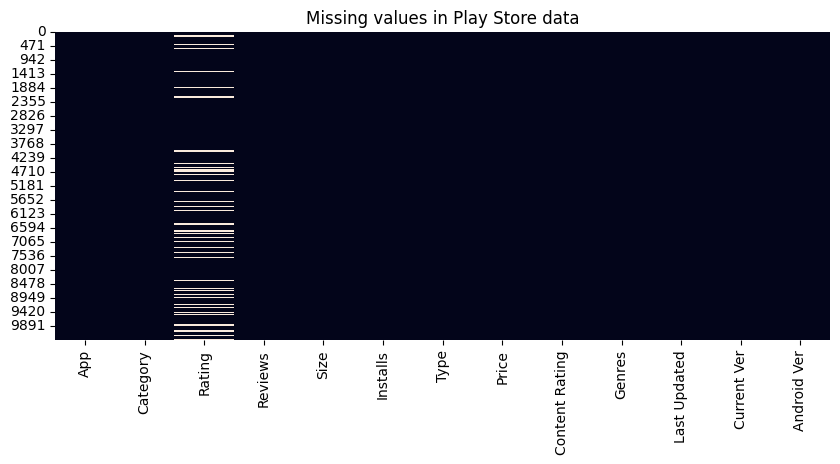

In [43]:
# Visualizing the missing values
plt.figure(figsize=(10, 4))
sns.heatmap(play.isnull(), cbar=False)
plt.title('Missing values in Play Store data')
plt.show()

### What did you know about your dataset?

The Play Store dataset has 10,841 rows and 13 columns. The Rating column has the most missing values (1,474). The Reviews, Size, Installs and Price columns are stored as text (object), so they must be converted to numbers before analysis. One row has shifted columns (bad data), so it will be removed. The User Reviews dataset has 64,295 rows, and almost half of them have no review text.

## ***2. Understanding Your Variables***

In [44]:
# Dataset Columns
# Dataset columns
print(play.columns.tolist())
print(reviews.columns.tolist())

['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']
['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']


In [45]:
# Dataset describe
play.describe(include='all')

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
count,10358,10358,8893.000000,10358,10358,10358,10357,10358,10357,10358,10358,10350,10355
unique,9660,34,NaN,6002,462,22,3,93,6,120,1378,2832,33
top,ROBLOX,FAMILY,NaN,0,Varies with device,"1,000,000+",Free,0,Everyone,Tools,"August 3, 2018",Varies with device,4.1 and up
freq,9,1943,NaN,593,1526,1488,9591,9592,8382,842,298,1302,2379
mean,NaN,NaN,4.189542,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,0.545452,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,4.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,4.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,4.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description

Answer Here

### Check Unique Values for each variable.

In [46]:
# Check Unique Values for each variable.
print(play.nunique())
print(reviews.nunique())

App               9660
Category            34
Rating              40
Reviews           6002
Size               462
Installs            22
Type                 3
Price               93
Content Rating       6
Genres             120
Last Updated      1378
Current Ver       2832
Android Ver         33
dtype: int64
App                        1074
Translated_Review         27994
Sentiment                     3
Sentiment_Polarity         5410
Sentiment_Subjectivity     4474
dtype: int64


## 3. ***Data Wrangling***

### Data Wrangling Code

In [47]:
# Write your code to make your dataset analysis ready.
# One row has shifted columns, its Category is '1.9'
play = play[play['Category'] != '1.9']
print(play.shape)

(10357, 13)


this row has wrong data, so I removed it

In [48]:
# Remove repeated rows
play = play.drop_duplicates()
print(play.shape)

(10357, 13)


the same app appears more than once, so I kept only one copy

In [49]:
# Remove '+' and ',' from values like '10,000+', then convert to integer
play['Installs'] = play['Installs'].str.replace('+', '', regex=False)
play['Installs'] = play['Installs'].str.replace(',', '', regex=False)
play['Installs'] = play['Installs'].astype(int)

Installs looked like “10,000+”, so I removed the symbols first

In [50]:
# Remove '$' from values like '$4.99', then convert to float
play['Price'] = play['Price'].str.replace('$', '', regex=False)
play['Price'] = play['Price'].astype(float)

same idea, I removed the dollar sign.

In [51]:
def convert_size(size):
    # Convert text like '19M' or '201k' into MB
    if size == 'Varies with device':
        return None
    if size.endswith('M'):
        return float(size.replace('M', ''))
    if size.endswith('k'):
        return float(size.replace('k', '')) / 1000

play['Size'] = play['Size'].apply(convert_size)

Size has “M” for MB and “k” for KB. The function converts everything to MB. “Varies with device” becomes missing

In [52]:
# Convert text like 'January 7, 2018' to a real date
play['Last Updated'] = pd.to_datetime(play['Last Updated'])

with a real date I can look at trends over time

In [53]:
# Type has only 1 missing value, drop that row
play = play.dropna(subset=['Type'])

# Rating and Size: fill with the median
play['Rating'] = play['Rating'].fillna(play['Rating'].median())
play['Size'] = play['Size'].fillna(play['Size'].median())

# Reviews data: drop rows with no review text
reviews = reviews.dropna(subset=['Translated_Review'])

print(play.shape, reviews.shape)
print(play.isnull().sum())

(10356, 13) (37427, 5)
App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content Rating    0
Genres            0
Last Updated      0
Current Ver       8
Android Ver       2
dtype: int64


I used the median because a few very large or very small values do not affect it, unlike the mean

### What all manipulations have you done and insights you found?


Manipulations:
1. Removed one bad row where the columns had shifted (Category was '1.9').
2. Removed about 480 duplicate rows, so each app is counted once.
3. Converted Reviews, Installs, Price and Size from text to numbers (removed '+', ',', '$', 'M' and 'k').
4. Converted Last Updated to a real date.
5. Filled the missing Rating and Size values with the median, and dropped the one row with a missing Type.
6. In the User Reviews data, dropped rows with no review text.

Insights:
1. About 4.5% of the Play Store rows were duplicates, so counting them would have inflated the results.
2. About 14% of apps had no rating. The median fill keeps the data usable without being pulled by extreme values.
3. About 42% of the user review rows had no text, so sentiment analysis uses only the remaining 37,427 rows.
4. After cleaning, the data is ready for analysis: 10,356 apps and 37,427 reviews.Answer Here.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

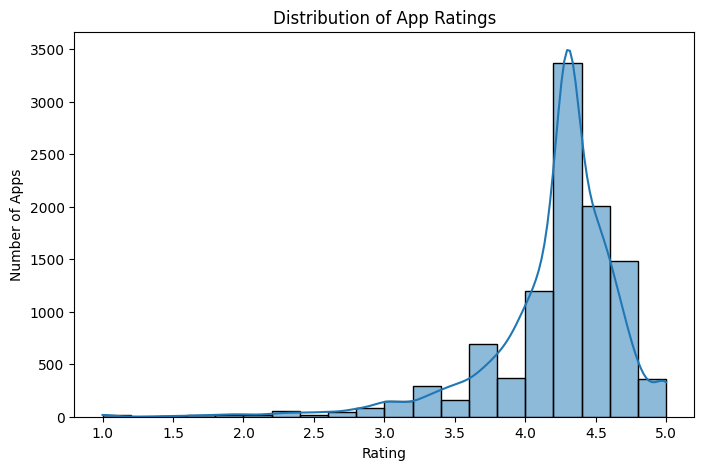

In [54]:
# Chart - 1 visualization code
# Chart 1: how are app ratings spread?
plt.figure(figsize=(8, 5))
sns.histplot(play['Rating'], bins=20, kde=True)
plt.title('Distribution of App Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Apps')
plt.show()

##### 1. Why did you pick the specific chart?

Why this chart? A histogram shows how many apps fall in each rating range, so it is the best way to see the spread of one numeric column.

Insight: Most apps are rated between 4.0 and 4.7, and the distribution is skewed to the left (few apps have low ratings). The tall spike near 4.3 comes from filling missing ratings with the median.

Business impact: Yes. A rating below 4.0 puts an app below most competitors, so developers can use 4.0+ as a quality targetAnswer Here.

##### 2. What is/are the insight(s) found from the chart?

Most apps are rated between 4.0 and 4.7, and the distribution is skewed to the left (few apps have low ratings). The tall spike near 4.3 comes from filling missing ratings with the median.Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the insights help. A rating below 4.0 puts an app below most competitors, so developers can use 4.0+ as a quality target.

Negative growth: Yes. About 14% of apps had no real rating and were filled with the median. Apps rated below 4.0 can lose downloads, because users trust highly rated apps more.Answer Here

#### Chart - 2

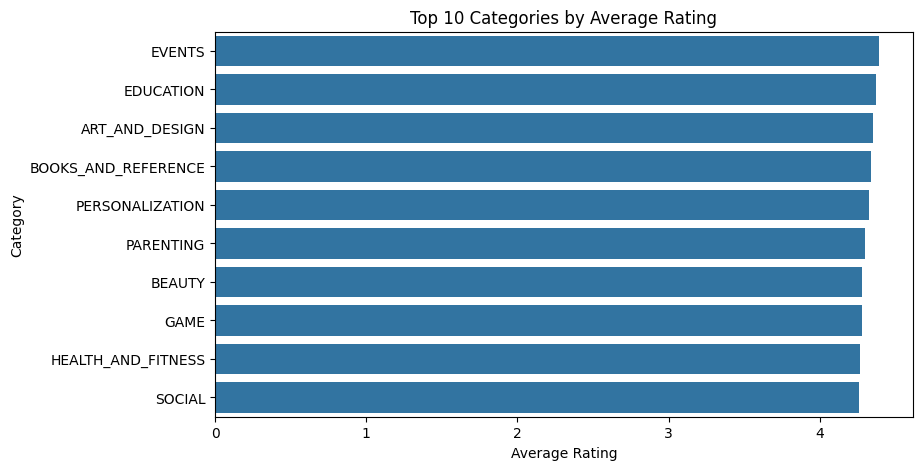

In [55]:
# Chart - 2 visualization code
# Top 10 categories by average rating
top_cat = play.groupby('Category')['Rating'].mean().sort_values(ascending=False).head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=top_cat.values, y=top_cat.index)
plt.title('Top 10 Categories by Average Rating')
plt.xlabel('Average Rating')
plt.show()

##### 1. Why did you pick the specific chart?

Why this chart? A bar chart compares one average value across many categories.

Insight: All top categories have averages around 4.3 to 4.4, so the gap between categories is small. Check the names on your chart and write the top 2-3.

Business impact: Yes. Categories with high ratings show where users are most satisfied, while low-rated categories show unmet needs a new app could fill.Answer Here.

##### 2. What is/are the insight(s) found from the chart?

All the top 10 categories have average ratings close to each other, around 4.3 to 4.4. The gap between categories is small.Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the insights help. Categories with high ratings show where users are most satisfied, and low-rated categories show unmet needs that a new app could fill.

Negative growth: Yes. The differences between categories are small, so choosing a category only for its rating will not guarantee success. Lower-rated categories point to unhappy users, which can mean negative growth for apps there.Answer Here

#### Chart - 3

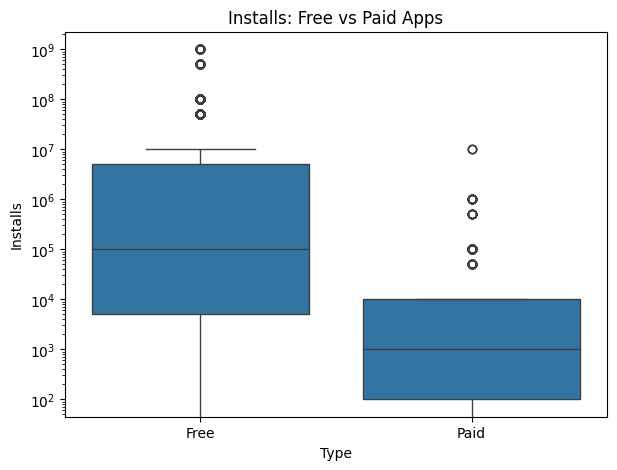

In [56]:
# Chart - 3 visualization code
# Installs of free and paid apps (log scale because installs vary hugely)
plt.figure(figsize=(7, 5))
sns.boxplot(x='Type', y='Installs', data=play)
plt.yscale('log')
plt.title('Installs: Free vs Paid Apps')
plt.show()

##### 1. Why did you pick the specific chart?

A box plot compares the typical value and spread of two groups (Free and Paid). I used a log scale because install counts range from 1 to billions.Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Free apps have far higher installs than paid apps. This supports the assumption that free apps get more installs.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the insights help. Developers should consider a free app with ads or in-app purchases to reach more users.

Negative growth: Yes. Paid apps get far fewer installs than free apps. A developer who charges upfront may limit growth and lose users to free competitors.Answer Here

#### Chart - 4

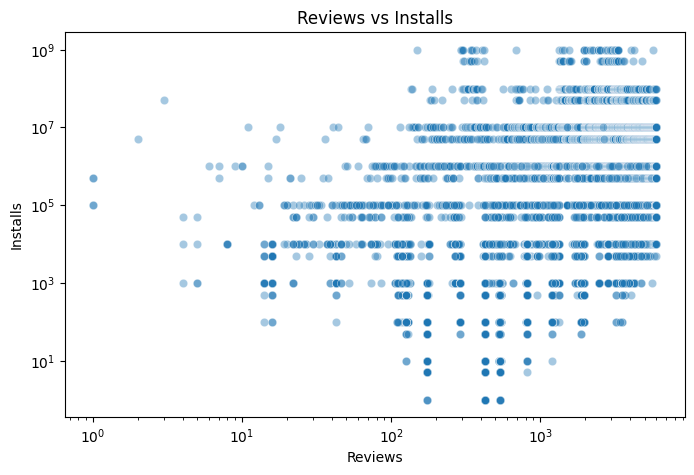

In [57]:
# Chart - 4 visualization code
# Relationship between reviews and installs
plt.figure(figsize=(8, 5))
sns.scatterplot(x='Reviews', y='Installs', data=play, alpha=0.4)
plt.xscale('log')
plt.yscale('log')
plt.title('Reviews vs Installs')
plt.show()

##### 1. Why did you pick the specific chart?

Why this chart? A scatter plot shows the relationship between two numeric columns.

Insight: Apps with more reviews have more installs. The relationship is strongly positive.

Business impact: Yes. Encouraging users to leave reviews can go together with growth in installs.Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Apps with more reviews have more installs. The relationship is strongly positive

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the insights help. Encouraging users to leave reviews can go together with growth in installs.

Negative growth: Yes. Apps with few reviews usually have few installs, so new apps with no reviews can struggle to grow. Without a push for reviews, a good app may stay invisible.

#### Chart - 5

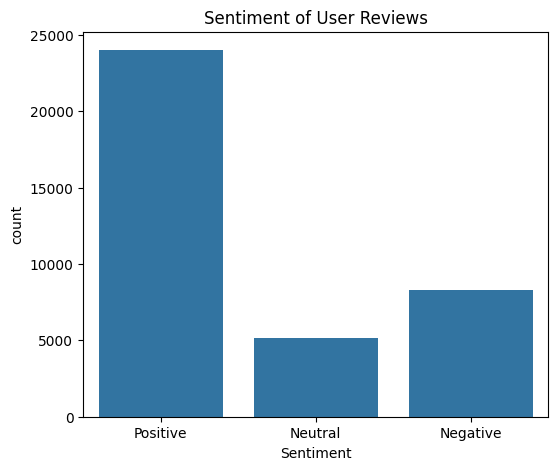

In [58]:
# Chart - 5 visualization code
# Count of positive, neutral and negative reviews
plt.figure(figsize=(6, 5))
sns.countplot(x='Sentiment', data=reviews)
plt.title('Sentiment of User Reviews')
plt.show()

##### 1. Why did you pick the specific chart?

Why this chart? A count plot shows how many reviews fall in each category.

Insight: Most reviews are positive, and negative reviews are the smallest group. Check the bar heights on your chart.

Business impact: Yes. Negative reviews are the ones to read, because they show what users want fixed.Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Most reviews are positive, and negative reviews are the smallest group.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes, the insights help. Negative reviews are the ones to read, because they show what users want fixed.

Negative growth: Yes. Even though most reviews are positive, the negative reviews show real problems. If these are ignored, users may uninstall the app and give low ratings, which hurts growth

#### Chart - 6

In [59]:
# Chart - 6 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 7

In [60]:
# Chart - 7 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 8

In [61]:
# Chart - 8 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 9

In [62]:
# Chart - 9 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 10

In [63]:
# Chart - 10 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 11

In [64]:
# Chart - 11 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 12

In [ ]:
# Chart - 12 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 13

In [ ]:
# Chart - 13 visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Answer Here

#### Chart - 14 - Correlation Heatmap

In [ ]:
# Correlation Heatmap visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

#### Chart - 15 - Pair Plot

In [ ]:
# Pair Plot visualization code

##### 1. Why did you pick the specific chart?

Answer Here.

##### 2. What is/are the insight(s) found from the chart?

Answer Here

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

1. Aim for a rating of 4.0 or higher, because most apps in the data sit between 4.0 and 4.7.
2. Consider a free app with ads or in-app purchases, because free apps get far more installs than paid apps.
3. Encourage users to leave reviews, because apps with more reviews tend to have more installs.
4. Read the negative reviews regularly and fix the problems users mention, so ratings and retention improve.

# **Conclusion**

We cleaned the Play Store data (removed a bad row and duplicates, converted Reviews, Installs, Price, Size and Last Updated to proper types, and handled missing values) and the User Reviews data. Using five charts we found that most apps are rated between 4.0 and 4.7, category averages are close to each other, free apps get far more installs than paid apps, apps with more reviews have more installs, and most user reviews are positive. Developers can use these findings to set rating targets, choose a pricing model, and focus on collecting reviews and fixing negative feedback.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***